# Poker Tilt: Live Demo
Four stages: **1. Preprocessing**, **2. Loss size**, **3. Tilt duration**, **4. Bad beat**.

Needs these files in the same folder in Colab: `bets.parquet`, `classified_losses.csv`, `post_event_comparison.csv`, `coverage.csv`.

In [4]:
# Setup: installs treys (hand evaluator) and finds the 4 data files
import subprocess, sys
subprocess.run([sys.executable, '-m', 'pip', '-q', 'install', 'treys', 'pyarrow'], check=False)
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
plt.rcParams.update({'figure.figsize': (8, 3.4), 'axes.spines.top': False, 'axes.spines.right': False})

NEEDED = ['bets.parquet', 'classified_losses.csv', 'post_event_comparison.csv', 'coverage.csv']
try:  # Colab: look in Drive, else ask for an upload
    from google.colab import drive, files
    drive.mount('/content/drive')
    D = Path('/content/drive/MyDrive/capstone')
    DATA = D if all((D / n).exists() for n in NEEDED) else Path('.')
    if not all((DATA / n).exists() for n in NEEDED):
        print('Upload:', NEEDED); files.upload()
except ImportError:
    DATA = Path('.')
missing = [n for n in NEEDED if not (DATA / n).exists()]
assert not missing, f'Missing files: {missing}'
bets = pd.read_parquet(DATA / 'bets.parquet')
print(f'{len(bets):,} bet/raise decisions, {bets.player.nunique():,} players, {bets.session_key.nunique():,} sessions')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
518,362 bet/raise decisions, 8,325 players, 35,325 sessions


## 1. Preprocessing
Raw hand histories were replayed action by action into one row per bet/raise. Each row carries the game state **before** the bet (pot, stack, facing a bet) plus loss history built only from **earlier** hands, so nothing leaks from the current hand.

In [5]:
import os, shutil; from google.colab import drive; drive.mount('/content/drive'); os.makedirs('/content/drive/MyDrive/capstone', exist_ok=True); [shutil.copy(f, '/content/drive/MyDrive/capstone/') for f in ['classified_losses.csv','coverage.csv','post_event_comparison.csv']]; shutil.copy('/content/drive/MyDrive/Colab Notebooks/bets.parquet', '/content/drive/MyDrive/capstone/'); print(os.listdir('/content/drive/MyDrive/capstone'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['classified_losses.csv', 'coverage.csv', 'post_event_comparison.csv', 'bets.parquet']


In [6]:
print('Columns grouped by what preprocessing added:')
groups = {
  'game state before the bet': ['street','pot_before_bb','stack_before_bb','to_call_bb','spr','n_active','is_facing_bet'],
  'the bet itself':            ['bet_to_bb','bet_to_pot'],
  'session + loss history':    ['session_key','hand_in_session','prev_net_bb','prev_was_loss','prev_big_loss','cum_net_bb','loss_streak','secs_since_prev_hand'],
}
for k, v in groups.items(): print(f'  {k}: {v}')

Columns grouped by what preprocessing added:
  game state before the bet: ['street', 'pot_before_bb', 'stack_before_bb', 'to_call_bb', 'spr', 'n_active', 'is_facing_bet']
  the bet itself: ['bet_to_bb', 'bet_to_pot']
  session + loss history: ['session_key', 'hand_in_session', 'prev_net_bb', 'prev_was_loss', 'prev_big_loss', 'cum_net_bb', 'loss_streak', 'secs_since_prev_hand']


In [7]:
# one player's session, in order: loss history updates hand by hand
s = bets[bets.session_key == bets.session_key.value_counts().index[0]].sort_values(['hand_in_session', 'action_idx'])
s[['hand_in_session','street','bet_to_bb','hand_net_bb','prev_net_bb','cum_net_bb','loss_streak']].head(12)

,hand_in_session,street,bet_to_bb,hand_net_bb,prev_net_bb,cum_net_bb,loss_streak
189135,0,preflop,3.0,3.0,NaN,0.0,0
189136,0,flop,4.0,3.0,NaN,0.0,0
189140,1,preflop,9.0,-61.8,3.0,3.0,0
189156,2,preflop,3.0,3.0,-61.8,-58.8,1
189157,2,river,7.0,3.0,-61.8,-58.8,1
189164,3,preflop,3.0,0.5,3.0,-55.8,0
189171,5,preflop,3.0,0.5,-0.5,-55.8,1
189180,6,preflop,9.0,-9.0,0.5,-55.3,0
189193,7,preflop,3.0,16.0,-9.0,-64.3,1
189194,7,flop,4.0,16.0,-9.0,-64.3,1


## 2. Loss size
Does a **bigger preceding loss** mean **bigger bets** on the next hand? Bet size is in big blinds (BB).

,mean,count,vs small loss
loss_cat,,,
Win / neutral (>=0),8.03,283310,-0.2%
Small loss (-10 to 0),8.04,204016,+0.0%
Moderate (-30 to -10),8.67,12612,+7.7%
Large (-60 to -30),10.03,3420,+24.7%
Huge (<-60),11.51,1856,+43.1%


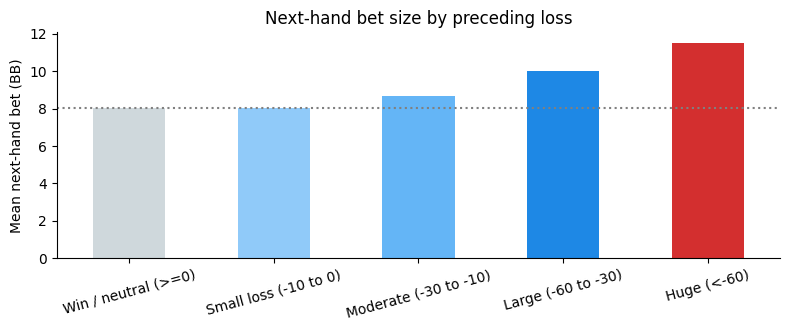

In [8]:
labels = ['Huge (<-60)', 'Large (-60 to -30)', 'Moderate (-30 to -10)', 'Small loss (-10 to 0)', 'Win / neutral (>=0)']
bets['loss_cat'] = pd.cut(bets.prev_net_bb, [-np.inf, -60, -30, -10, 0, np.inf], right=False, labels=labels)
ls = bets.groupby('loss_cat', observed=True).bet_to_bb.agg(['mean', 'count']).loc[labels[::-1]]
base = ls.loc['Small loss (-10 to 0)', 'mean']
ls['vs small loss'] = (ls['mean'] / base - 1).map('{:+.1%}'.format)
display(ls.round(2))
ax = ls['mean'].plot.bar(color=['#cfd8dc','#90caf9','#64b5f6','#1e88e5','#d32f2f'], rot=15)
ax.axhline(base, ls=':', c='gray'); ax.set_ylabel('Mean next-hand bet (BB)'); ax.set_xlabel('')
ax.set_title('Next-hand bet size by preceding loss'); plt.tight_layout(); plt.show()

## 3. Tilt duration
After a large loss (worse than -30 BB), how many hands until bet sizes drift back toward normal?

,mean bet (BB),bets
hands after loss,,
1,10.56,4781
2,9.79,4457
3,9.59,4352
4,9.02,4033
5,9.20,4007
6,9.93,3893
7,9.87,3705
8,9.47,3594
9,9.86,3449


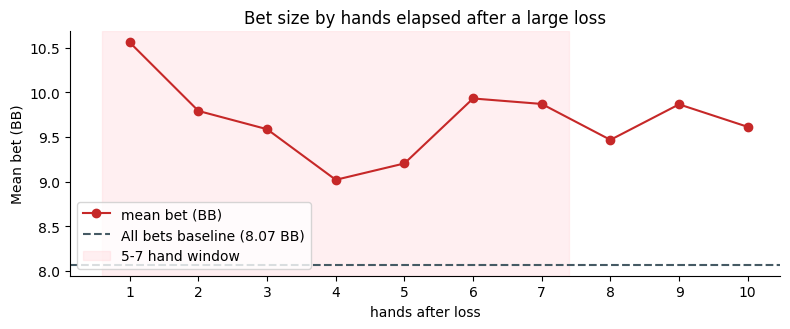

In [9]:
hands = bets.groupby(['session_key', 'hand_in_session'], as_index=False).hand_net_bb.first()
big = hands[hands.hand_net_bb < -30][['session_key', 'hand_in_session']]
rows = []
for k in range(1, 11):
    x = bets.merge(big.assign(hand_in_session=big.hand_in_session + k), on=['session_key', 'hand_in_session'])
    rows.append({'hands after loss': k, 'mean bet (BB)': x.bet_to_bb.mean(), 'bets': len(x)})
td = pd.DataFrame(rows).set_index('hands after loss')
baseline = bets.bet_to_bb.mean()
display(td.round(2))
ax = td['mean bet (BB)'].plot(marker='o', c='#c62828')
ax.axhline(baseline, ls='--', c='#455a64', label=f'All bets baseline ({baseline:.2f} BB)')
ax.axvspan(0.6, 7.4, color='#ffcdd2', alpha=.3, label='5-7 hand window')
ax.set_xticks(range(1, 11)); ax.set_ylabel('Mean bet (BB)'); ax.legend(); ax.set_title('Bet size by hands elapsed after a large loss')
plt.tight_layout(); plt.show()

## 4. Bad beat
A **bad beat** = heads-up all-in called, the loser had **>= 70% equity**, and lost **>= 30 BB**. Equity is the loser's win chance at the moment the chips went in, found by enumerating every remaining board.

In [10]:
from itertools import combinations
from treys import Card, Evaluator
CARDS = [r + s for r in '23456789TJQKA' for s in 'cdhs']
def equity(board, hero, villain):
    ev = Evaluator(); used = set(board) | {hero[:2], hero[2:], villain[:2], villain[2:]}
    deck = [c for c in CARDS if c not in used]
    hc = [Card.new(hero[:2]), Card.new(hero[2:])]; vc = [Card.new(villain[:2]), Card.new(villain[2:])]
    bc = [Card.new(c) for c in board]; w = t = n = 0
    for extra in combinations(deck, 5 - len(board)):
        fin = bc + [Card.new(c) for c in extra]; h, v = ev.evaluate(fin, hc), ev.evaluate(fin, vc); n += 1
        w += h < v; t += h == v
    return (w + t / 2) / n

for board in (['9s', '7d', '2c'], ['Ks', '7d', '2c']):
    e = equity(board, 'AhAd', 'KhKd')
    print(f'AhAd vs KhKd, flop {board}: AA equity {e:.1%}  ->', 'bad beat if AA loses' if e >= .7 else 'AA is the underdog, not a bad beat')

AhAd vs KhKd, flop ['9s', '7d', '2c']: AA equity 91.6%  -> bad beat if AA loses
AhAd vs KhKd, flop ['Ks', '7d', '2c']: AA equity 8.6%  -> AA is the underdog, not a bad beat


Funnel: 323,464 hands -> 1,564 heads-up all-ins -> 1,231 with both hands shown -> 1,098 losses of 30+ BB


,events
event_type,
other_large_loss,982
bad_beat,116


,hand_id,loss_bb,equity,allin_street
33,3037469732,-53.70,0.96,river
838,3085709412,-120.20,0.96,river
841,3085732646,-70.65,0.96,river
261,3049820264,-107.15,0.95,4
381,3059520166,-100.10,0.95,4


,event_type,unique_events,betting_decisions,flagged_bets,flag_rate_percent
0,bad_beat,116,83,3,3.6
1,other_large_loss,982,616,33,5.4


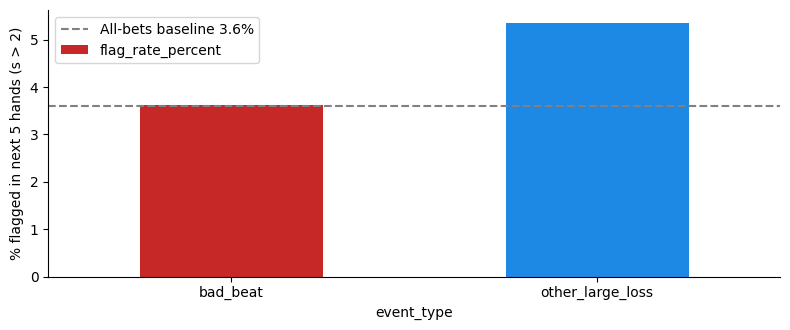

In [11]:
ev = pd.read_csv(DATA / 'classified_losses.csv'); res = pd.read_csv(DATA / 'post_event_comparison.csv'); cov = pd.read_csv(DATA / 'coverage.csv', index_col=0).iloc[:, 0]
print('Funnel:', f"{cov['hands']:,} hands -> {cov['heads_up_allin']:,} heads-up all-ins -> {cov['allin_with_cards']:,} with both hands shown -> {cov['large_allin_losses']:,} losses of 30+ BB")
display(ev.event_type.value_counts().to_frame('events'))
display(ev[ev.event_type == 'bad_beat'].sort_values('equity', ascending=False).head(5)[['hand_id', 'loss_bb', 'equity', 'allin_street']].round(2))
display(res.round(1))
ax = res.set_index('event_type').flag_rate_percent.plot.bar(color=['#c62828', '#1e88e5'], rot=0)
ax.axhline(3.6, ls='--', c='gray', label='All-bets baseline 3.6%'); ax.set_ylabel('% flagged in next 5 hands (s > 2)'); ax.legend()
plt.tight_layout(); plt.show()

**Read-out:** bad beats (3.6% flagged) did not look different from baseline; ordinary large losses were higher (5.4%). Only 3 flagged bets after bad beats, so this is a small-sample, association-only result.